# 02 — Preprocessing & Chunking (Structure-Aware)

**Tujuan:** menyiapkan basis pengetahuan: memecah teks interim tiap dokumen menjadi
chunk siap-index, dengan strategi *structure-aware* (§6 `perancangan.md`).

Heading `BAB` adalah batas KERAS (selalu memulai chunk baru); heading lain (`A.`,
`2.1.`, dst) adalah batas LUNAK — hanya mengisi metadata `section_heading`, tidak
memaksa pemotongan, supaya sub-bagian pendek tidak pecah jadi chunk-chunk kecil.
Paragraf yang lebih panjang dari `chunk_size` dipecah lebih lanjut lewat kaskade
paragraf → kalimat → kata → karakter, dengan overlap adaptif antar-chunk sehingga
`chunk_size` tidak pernah dilanggar (lihat `src/chunking.py` untuk detail algoritma).

**INPUT:** `../data/processed/documents.jsonl`, `../data/interim/{doc_id}.txt`

**OUTPUT:** `../data/processed/chunks.jsonl`

**Perkiraan runtime:** < 1 menit untuk korpus saat ini

**Perkiraan biaya API:** Rp 0 — tidak ada panggilan LLM di notebook ini

**Assert di notebook ini:** `chunk_id` unik lintas seluruh dokumen; `page_start <=
page_end`; setiap chunk `min_chunk_chars <= n_chars <= chunk_size`; tidak ada teks kosong.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, "../src")

In [2]:
import json
import random
from pathlib import Path

import pandas as pd

from config import load_config, set_seed

cfg = load_config("../configs/base.yaml")
set_seed(cfg.seed)

chunk_strategy = f"structure_pack_{cfg.chunking.chunk_size}"
chunk_strategy

'structure_pack_2000'

## Muat katalog dokumen

In [3]:
documents = [json.loads(line) for line in open("../data/processed/documents.jsonl", encoding="utf-8")]

skipped_not_extractable = [d["doc_id"] for d in documents if not d["extractable"]]
documents = [d for d in documents if d["extractable"]]

print(f"{len(documents)} dokumen extractable akan diproses")
if skipped_not_extractable:
    print(f"Dilewati (extractable=false): {skipped_not_extractable}")

9 dokumen extractable akan diproses


## Chunking per dokumen

In [4]:
import chunking

all_records = []
per_doc_stats = []

for doc in documents:
    interim_path = Path("../data/interim") / f"{doc['doc_id']}.txt"
    pages = chunking.parse_interim_pages(interim_path)

    records, stats = chunking.build_chunk_records(
        doc_id=doc["doc_id"],
        pages=pages,
        chunk_strategy=chunk_strategy,
        chunk_size=cfg.chunking.chunk_size,
        chunk_overlap=cfg.chunking.chunk_overlap,
        min_chunk_chars=cfg.chunking.min_chunk_chars,
        max_dot_ratio=cfg.chunking.max_dot_ratio,
        soft_max=cfg.chunking.soft_max,
    )
    all_records.extend(records)
    per_doc_stats.append({"doc_id": doc["doc_id"], "n_pages": len(pages), **stats})
    print(f"{doc['doc_id']}: {stats}")

pd.DataFrame(per_doc_stats)

lpmb-2026-arah-kebijakan-unair-dalam-pengmas: {'n_front_matter_units_dropped': 0, 'n_raw_chunks': 18, 'n_kept': 18, 'n_merged_orphan': 0, 'n_dropped_short': 0, 'n_dropped_dot_noise': 0}
lpmb-2026-buku-panduan-bbk-2026-untuk-mahasiswa: {'n_front_matter_units_dropped': 2, 'n_raw_chunks': 106, 'n_kept': 80, 'n_merged_orphan': 21, 'n_dropped_short': 0, 'n_dropped_dot_noise': 0}
lpmb-2026-launching-pengmas-lpmb-2026-sesi: {'n_front_matter_units_dropped': 0, 'n_raw_chunks': 7, 'n_kept': 7, 'n_merged_orphan': 0, 'n_dropped_short': 0, 'n_dropped_dot_noise': 0}
lpmb-2026-materi-kontribusi-pengmas-sdgs: {'n_front_matter_units_dropped': 0, 'n_raw_chunks': 9, 'n_kept': 9, 'n_merged_orphan': 0, 'n_dropped_short': 0, 'n_dropped_dot_noise': 0}
lpmb-2026-panduan-bbk-jenis-internasional-2026: {'n_front_matter_units_dropped': 0, 'n_raw_chunks': 9, 'n_kept': 9, 'n_merged_orphan': 0, 'n_dropped_short': 0, 'n_dropped_dot_noise': 0}
lpmb-2026-panduan-bbk-jenis-penyetaraan-2026: {'n_front_matter_units_droppe

lpmb-2026-panduan-usulan-pengmas-internal-universitas-airlan: {'n_front_matter_units_dropped': 13, 'n_raw_chunks': 313, 'n_kept': 120, 'n_merged_orphan': 2, 'n_dropped_short': 0, 'n_dropped_dot_noise': 0}
lpmb-2026-pengabdian-masyarakat-yang-berdampak-materi: {'n_front_matter_units_dropped': 0, 'n_raw_chunks': 16, 'n_kept': 16, 'n_merged_orphan': 0, 'n_dropped_short': 0, 'n_dropped_dot_noise': 0}


,doc_id,n_pages,n_front_matter_units_dropped,n_raw_chunks,n_kept,n_merged_orphan,n_dropped_short,n_dropped_dot_noise
0,lpmb-2026-arah-kebijakan-unair-dalam-pengmas,24,0,18,18,0,0,0
1,lpmb-2026-buku-panduan-bbk-2026-untuk-mahasiswa,68,2,106,80,21,0,0
2,lpmb-2026-launching-pengmas-lpmb-2026-sesi,13,0,7,7,0,0,0
3,lpmb-2026-materi-kontribusi-pengmas-sdgs,27,0,9,9,0,0,0
4,lpmb-2026-panduan-bbk-jenis-internasional-2026,15,0,9,9,0,0,0
5,lpmb-2026-panduan-bbk-jenis-penyetaraan-2026,12,0,10,10,0,0,0
6,lpmb-2026-panduan-teknis-pengusulan-proposal-p...,29,0,3,3,0,0,0
7,lpmb-2026-panduan-usulan-pengmas-internal-univ...,99,13,313,120,2,0,0
8,lpmb-2026-pengabdian-masyarakat-yang-berdampak...,49,0,16,16,0,0,0


## Diagnostik: distribusi panjang chunk

count     272.000000
mean     1184.216912
std       602.731569
min        37.000000
25%       688.750000
50%      1170.000000
75%      1749.000000
max      2621.000000
dtype: float64


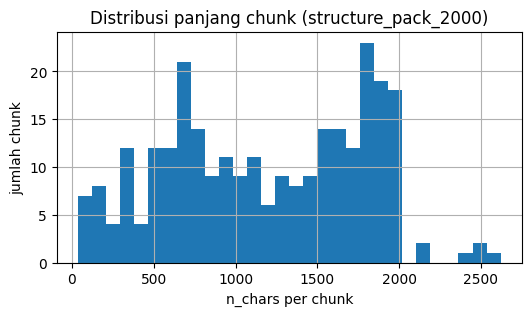

Chunk dengan section_heading terisi: 264/272 (97%)
Chunk tabel (is_table=True): 92/272
  n_chars tabel -- min: 335, max: 2621, rata-rata: 1220


In [5]:
import matplotlib.pyplot as plt

n_chars_series = pd.Series([r["n_chars"] for r in all_records])
print(n_chars_series.describe())

fig, ax = plt.subplots(figsize=(6, 3))
n_chars_series.hist(bins=30, ax=ax)
ax.set_xlabel("n_chars per chunk")
ax.set_ylabel("jumlah chunk")
ax.set_title(f"Distribusi panjang chunk ({chunk_strategy})")
plt.show()

n_with_heading = sum(1 for r in all_records if r["section_heading"])
print(f"Chunk dengan section_heading terisi: {n_with_heading}/{len(all_records)} "
      f"({n_with_heading / len(all_records):.0%})")

n_table_chunks = sum(1 for r in all_records if r["is_table"])
print(f"Chunk tabel (is_table=True): {n_table_chunks}/{len(all_records)}")
if n_table_chunks:
    table_n_chars = pd.Series([r["n_chars"] for r in all_records if r["is_table"]])
    print(f"  n_chars tabel -- min: {table_n_chars.min()}, max: {table_n_chars.max()}, rata-rata: {table_n_chars.mean():.0f}")


## Inspeksi manual: 3 chunk acak

Periksa apakah `section_heading` masuk akal dan teks tidak terpotong aneh —
ini pengecekan mata terhadap heuristik heading/paragraf di `src/chunking.py`.

In [6]:
for r in random.sample(all_records, k=3):
    print(f"chunk_id: {r['chunk_id']}")
    print(f"halaman: {r['page_start']}-{r['page_end']}  |  section_heading: {r['section_heading']!r}")
    print(f"n_chars: {r['n_chars']}  n_tokens(est): {r['n_tokens']}")
    print(r["text"][:400])
    print("-" * 80)

chunk_id: lpmb-2026-buku-panduan-bbk-2026-untuk-mahasiswa::p31::c001
halaman: 31-31  |  section_heading: 'BAB II JENIS BBK > 2.3 BBK Penyetaraan'
n_chars: 1628  n_tokens(est): 407
(lanjutan) BBK Penyetaraan secara umum dapat dibagi menjadi dua kelompok, yaitu:
2. BBK Penyetaraan berdasarkan pencapaian/prestasi, yaitu pencapaian/prestasi yang didapatkan oleh mahasiswa dari suatu kegiatan yang telah ditetapkan kriterianya dengan kriteria sebagai berikut:
a. Mahasiswa lolos pendanaan oleh Dikti di kegiatan PIMNAS pada kategori PKMM (poster dan/atau presenter) dan di kegiatan P
--------------------------------------------------------------------------------
chunk_id: lpmb-2026-arah-kebijakan-unair-dalam-pengmas::p13::c002
halaman: 13-18  |  section_heading: '8 SDGs UNAIR tembus Top #30 Dunia tahun 2025'
n_chars: 2457  n_tokens(est): 614
Source: THE Data Point
Skema Pengabdian kepada Masyarakat Reguler Pendanaan Pemerintah dan Internal UNAIR DPPM (Direktorat Penelitian dan Pengabdian kepada

## Inspeksi manual: chunk tabel

Verifikasi bahwa tabel (mis. Tabel 2.3 di halaman 22, yang sebelumnya hancur oleh `extract_text()` — nilai pendanaan/skema/jumlah anggota terinterleaving acak lintas kolom) sekarang menjadi satu chunk Markdown utuh dengan tiap baris tabel tetap koheren.

In [7]:
table_chunks = [r for r in all_records if r["is_table"]]
print(f"Total chunk tabel: {len(table_chunks)}")

sample_table = next((r for r in table_chunks if r["page_start"] == 22), table_chunks[0])
print(f"chunk_id: {sample_table['chunk_id']}")
print(f"halaman: {sample_table['page_start']}-{sample_table['page_end']}  n_chars: {sample_table['n_chars']}")
print(sample_table["text"])

Total chunk tabel: 92
chunk_id: lpmb-2026-materi-kontribusi-pengmas-sdgs::p22::c001
halaman: 22-23  n_chars: 2413
SDG 12: KONSUMSI DAN PRODUKSI YANG BERTANGGUNG JAWAB SDG 12 bertujuan untuk menjamin pola produksi dan konsumsi yang berkelanjutan. mengakhir segala bentuk kemiskinan. Secara rata-rata, setiap orang membuang 120 kilogram makanan per tahunnya. Edukasi Pengolahan Sampah Mahasiswa KKN UNAIR berkolaborasi dengan Desa Pucangtelu untuk mengedukasi warga setempat dalam pengolahan sampah. Kolaborasi ini bertujuan untuk meningkatkan kesadaran dan kemampuan masyarakat dalam mendaur ulang limbah, khususnya sampah plastik.: SDG 14: EKOSISTEM LAUTAN SDG 14 bertujuan untuk melindungi, memulihkan, dan mendorong pemanfaatan ekosistem darat yang berkelanjutan, mengelola hutan secara berkelanjutan, memerangi penggurunan, serta menghentikan dan membalikkan degradasi lahan dan menghentikan hilangnya keanekaragaman hayati. Pada kondisi saat ini, sebanyak 11-26 juta ikan ditangkap secara illegal

## ASSERT

In [8]:
assert len(all_records) > 0, "Tidak ada chunk dihasilkan"

chunk_ids = [r["chunk_id"] for r in all_records]
assert len(chunk_ids) == len(set(chunk_ids)), "chunk_id tidak unik lintas dokumen"

from collections import Counter

n_per_induk = Counter(
    (r["doc_id"], (r["section_heading"] or "").rsplit(" > ", 1)[0])
    for r in all_records if not r["is_table"] and not r.get("is_form")
)
chunk_pendek = []

for r in all_records:
    assert r["page_start"] <= r["page_end"], f"page_start > page_end: {r['chunk_id']}"
    assert r["text"].strip(), f"teks kosong: {r['chunk_id']}"
    if not r["is_table"] and not r.get("is_form"):
        # Chunk tabel SENGAJA dikecualikan dari kedua batas ini -- satu
        # tabel = satu chunk utuh, berapa pun ukurannya (lihat
        # src/chunking.py::build_chunk_records dan README).
        # Chunk pendek hanya boleh bila tak punya saudara untuk digabung
        # (satu-satunya chunk non-tabel di bawah induk judulnya).
        if r["n_chars"] < cfg.chunking.min_chunk_chars:
            induk = (r["doc_id"], (r["section_heading"] or "").rsplit(" > ", 1)[0])
            assert n_per_induk[induk] == 1, (
                f"n_chars di bawah batas padahal punya saudara: {r['chunk_id']} -> {r['n_chars']}"
            )
            chunk_pendek.append((r["chunk_id"], r["n_chars"]))
        # Batas atas soft_max (bukan chunk_size): paragraf tunggal sepanjang
        # (chunk_size, soft_max] sengaja dibiarkan jadi satu chunk sendiri
        # tanpa dipaksa lewat recursive_chunk (lihat README, rekomendasi
        # soft_max/toleransi luapan 1.3x).
        assert r["n_chars"] <= cfg.chunking.soft_max, (
            f"n_chars melebihi soft_max pada chunk non-tabel: {r['chunk_id']} -> {r['n_chars']}"
        )
    assert r["chunk_strategy"] == chunk_strategy, f"chunk_strategy tidak konsisten: {r['chunk_id']}"

print("Semua assert lolos.")
print(f"Chunk non-tabel < min_chunk_chars tanpa saudara: {chunk_pendek}")

Semua assert lolos.
Chunk non-tabel < min_chunk_chars tanpa saudara: [('lpmb-2026-arah-kebijakan-unair-dalam-pengmas::p05::c002', 204), ('lpmb-2026-arah-kebijakan-unair-dalam-pengmas::p05::c003', 146), ('lpmb-2026-arah-kebijakan-unair-dalam-pengmas::p05::c004', 206), ('lpmb-2026-arah-kebijakan-unair-dalam-pengmas::p05::c005', 118), ('lpmb-2026-arah-kebijakan-unair-dalam-pengmas::p06::c001', 136), ('lpmb-2026-arah-kebijakan-unair-dalam-pengmas::p20::c001', 37), ('lpmb-2026-buku-panduan-bbk-2026-untuk-mahasiswa::p58::c001', 92), ('lpmb-2026-buku-panduan-bbk-2026-untuk-mahasiswa::p58::c002', 70), ('lpmb-2026-buku-panduan-bbk-2026-untuk-mahasiswa::p58::c003', 109), ('lpmb-2026-buku-panduan-bbk-2026-untuk-mahasiswa::p67::c001', 178), ('lpmb-2026-launching-pengmas-lpmb-2026-sesi::p01::c001', 125), ('lpmb-2026-launching-pengmas-lpmb-2026-sesi::p02::c001', 136), ('lpmb-2026-panduan-bbk-jenis-internasional-2026::p11::c001', 201), ('lpmb-2026-panduan-bbk-jenis-penyetaraan-2026::p10::c001', 215)]

## Tulis `chunks.jsonl`

In [9]:
out_path = "../data/processed/chunks.jsonl"
chunking.write_chunks_jsonl(all_records, out_path)
print(f"Ditulis {len(all_records)} chunk ke {out_path}")

Ditulis 272 chunk ke ../data/processed/chunks.jsonl


## Ringkasan

In [10]:
total_dropped = sum(s["n_dropped_short"] for s in per_doc_stats)
total_dropped_dot_noise = sum(s["n_dropped_dot_noise"] for s in per_doc_stats)
total_merged_orphan = sum(s["n_merged_orphan"] for s in per_doc_stats)
print(f"Dokumen diproses: {len(documents)} (dilewati: {len(skipped_not_extractable)})")
print(f"Total chunk: {len(all_records)}")
print(f"Total dibuang (< {cfg.chunking.min_chunk_chars} karakter): {total_dropped}")
print(f"Total dibuang (rasio titik > {cfg.chunking.max_dot_ratio}, mis. daftar isi): {total_dropped_dot_noise}")
print(f"Total chunk yatim dilebur ke tetangga (bukan dibuang): {total_merged_orphan}")
print(f"Rata-rata n_chars: {n_chars_series.mean():.0f}")
print(f"Chunk dengan section_heading: {n_with_heading}/{len(all_records)} ({n_with_heading / len(all_records):.0%})")
print(f"Chunk tabel: {n_table_chunks}/{len(all_records)}")
print(f"chunk_strategy: {chunk_strategy}")

Dokumen diproses: 9 (dilewati: 0)
Total chunk: 272
Total dibuang (< 250 karakter): 0
Total dibuang (rasio titik > 0.2, mis. daftar isi): 0
Total chunk yatim dilebur ke tetangga (bukan dibuang): 23
Rata-rata n_chars: 1184
Chunk dengan section_heading: 264/272 (97%)
Chunk tabel: 92/272
chunk_strategy: structure_pack_2000
